In [2]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent
DB = ROOT / "data" / "Chinook_Sqlite.sqlite"
assert DB.exists(), f"Base introuvable : {DB}"


def run(fichier):
    """Exécute un fichier du dossier sql/ et renvoie un DataFrame."""
    sql = (ROOT / "sql" / fichier).read_text(encoding="utf-8")
    con = sqlite3.connect(DB)
    try:
        return pd.read_sql_query(sql, con)
    finally:
        con.close()

In [3]:
PAPER, INK, MUTED, RULE, ACCENT = "#FAFAF7", "#1A1A1A", "#76756F", "#E5E4DF", "#D64B2A"

plt.rcParams.update({
    "figure.facecolor": PAPER,
    "axes.facecolor": PAPER,
    "savefig.facecolor": PAPER,
    "axes.edgecolor": RULE,
    "axes.labelcolor": MUTED,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 11,
    "figure.dpi": 110,
    "savefig.dpi": 200,
})

In [4]:
ca_annee = run("01_ca_par_annee.sql")
print(ca_annee.columns.tolist())
ca_annee

['annee', 'nb_factures', 'chiffre_affaires']


,annee,nb_factures,chiffre_affaires
0,2009,83,449.46
1,2010,83,481.45
2,2011,83,469.58
3,2012,83,477.53
4,2013,80,450.58


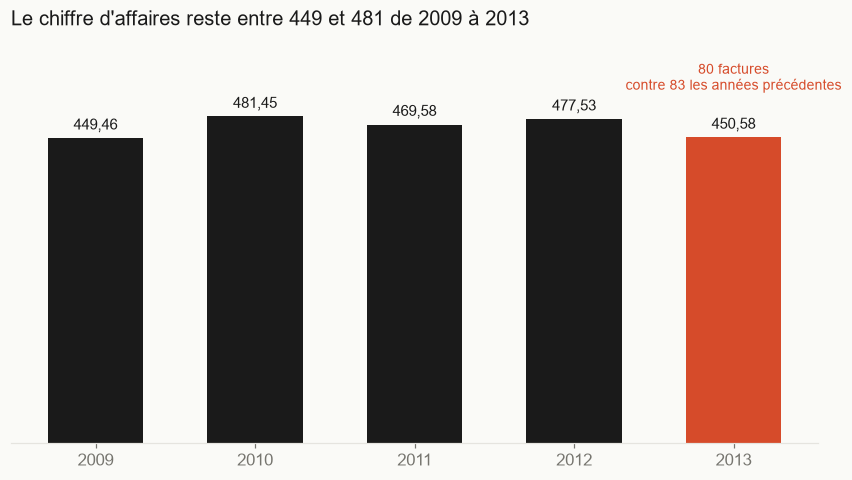

In [5]:
annees = ca_annee["annee"].astype(str)
valeurs = ca_annee["chiffre_affaires"]

fig, ax = plt.subplots(figsize=(8, 4.5))

couleurs = [ACCENT if a == "2013" else INK for a in annees]
barres = ax.bar(annees, valeurs, color=couleurs, width=0.6)

for barre, valeur in zip(barres, valeurs):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        valeur + 8,
        f"{valeur:.2f}".replace(".", ","),
        ha="center", va="bottom", color=INK, fontsize=10,
    )

# Note sur 2013 (index 4 sur l'axe des catégories)
ax.text(4, 515, "80 factures\ncontre 83 les années précédentes",
        ha="center", va="bottom", color=ACCENT, fontsize=9)

ax.set_ylim(0, 580)
ax.spines["left"].set_visible(False)
ax.tick_params(left=False, labelleft=False)
ax.set_title("Le chiffre d'affaires reste entre 449 et 481 de 2009 à 2013",
             loc="left", fontsize=13, color=INK, pad=16)

fig.tight_layout()
fig.savefig(ROOT / "docs" / "01_ca_par_annee.png", bbox_inches="tight")
plt.show()

In [6]:
ca_pays = run("02_ca_par_pays.sql")
print(ca_pays.columns.tolist())
ca_pays

['pays', 'nb_clients', 'nb_factures', 'chiffre_affaires', 'ca_par_client', 'part_pct']


,pays,nb_clients,nb_factures,chiffre_affaires,ca_par_client,part_pct
0,USA,13,91,523.06,40.24,22.5
1,Canada,8,56,303.96,37.99,13.1
2,France,5,35,195.10,39.02,8.4
3,Brazil,5,35,190.10,38.02,8.2
4,Germany,4,28,156.48,39.12,6.7
5,United Kingdom,3,21,112.86,37.62,4.8
6,Czech Republic,2,14,90.24,45.12,3.9
7,Portugal,2,14,77.24,38.62,3.3
8,India,2,13,75.26,37.63,3.2
9,Chile,1,7,46.62,46.62,2.0


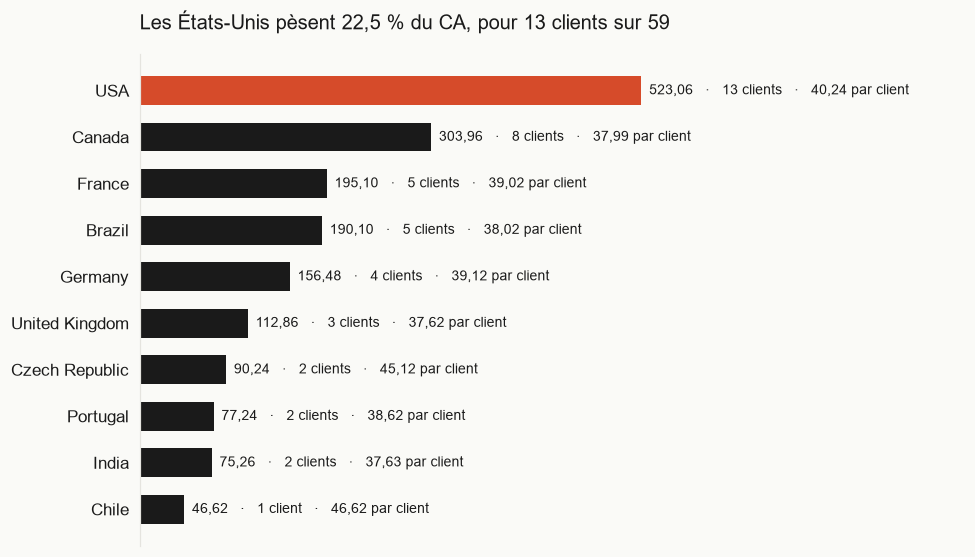

In [7]:
def fr(x):
    """Nombre avec 2 décimales et virgule."""
    return f"{x:.2f}".replace(".", ",")


pays = ca_pays["pays"]
valeurs = ca_pays["chiffre_affaires"]

fig, ax = plt.subplots(figsize=(9, 5.2))

couleurs = [ACCENT if p == "USA" else INK for p in pays]
barres = ax.barh(pays, valeurs, color=couleurs, height=0.62)
ax.invert_yaxis()  # le plus grand en haut

for barre, (_, ligne) in zip(barres, ca_pays.iterrows()):
    n = int(ligne["nb_clients"])
    mot = "client" if n == 1 else "clients"
    texte = f"{fr(ligne['chiffre_affaires'])}   ·   {n} {mot}   ·   {fr(ligne['ca_par_client'])} par client"
    ax.text(
        barre.get_width() + 8,
        barre.get_y() + barre.get_height() / 2,
        texte,
        va="center", ha="left", color=INK, fontsize=9,
    )

ax.set_xlim(0, 860)
ax.spines["bottom"].set_visible(False)
ax.tick_params(bottom=False, labelbottom=False, left=False)
ax.tick_params(axis="y", labelcolor=INK)
ax.set_title("Les États-Unis pèsent 22,5 % du CA, pour 13 clients sur 59",
             loc="left", fontsize=13, color=INK, pad=16)

fig.tight_layout()
fig.savefig(ROOT / "docs" / "02_ca_par_pays.png", bbox_inches="tight")
plt.show()